# Phase 25E - Canonical Resource-Gate Policy Evaluation

**Method**: `RA-MedFiLM-BARR` - resource-gate revision `ra_medfilm_barr_resource_gate_v1_0`.

This notebook evaluates the **45 frozen prospective policies** (comparators C3-C8 across the
five fixed budgets and the four lambda values) on the 4957 `ROUTER_DEVELOPMENT` rows, after
joining the frozen OOF memberships to the frozen Phase25C paired-gain outcomes.

**Hard scope**: `ROUTER_DEVELOPMENT` only. `ROUTER_HOLDOUT` (875), `VAL808` and `TEST` are
never read. The oracle (C10) is a **nondeployable development upper bound**. TEST is locked
until Phase39. No lambda is selected; the resource gate is not calibrated for deployment here
beyond the frozen DEV-score thresholds.

Ordering guarantee: memberships, statistics and final-router DEV thresholds were frozen
**before** any outcome column was opened (`phase25e_pre_outcome_freeze.json`).

In [1]:
from pathlib import Path
import base64, hashlib, io, json
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image

ROOT = Path.cwd()
while not (ROOT / 'reports/audits/phase25e_adjudication.json').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
INPUTS = {
"reports/audits/phase25e_adjudication.json": "c4a0ce17d8bd769c0bd2588bfcfb5b587ef20622e308b777b5757f8fa6f04a7c",
"reports/audits/phase25e_adjudication_reconciled.json": "239abea983866dc791c4efdb6a767fb68adb099f9509f5aa267bbd40e7822bbc",
"reports/audits/phase25e_comparator_direction_contract_v1_0.json": "7652e7bdf65722c0877e17f35e565f0ee809aaff8c99448928372a71f58e2beb",
"reports/audits/phase25e_cost_variability_and_policy_redundancy_audit.json": "72546015f08163e0b0269e08f47edcea86519cdf4a246b88da0a7f0d761949c2",
"reports/audits/phase25e_evaluation_statistics_contract_v1_0.json": "fc90a1362a06eda342d987d2f6e1e12a1190ac650d7bb0db1234514a297644af",
"reports/audits/phase25e_execution_metrics_contract_v1_0.json": "24fa469ac4623665654adde88bab4e23b714b1a5199372c3b64603bacf47bbc6",
"reports/audits/phase25e_final_router_dev_calibration.json": "9696f5d665913bcecf1f2343bfc4b7a9e2b81815117e4d151ad319643306f0e5",
"reports/audits/phase25e_fixed_budget_contract_v1_0.json": "c8ade16f835617c23aa6c363e2f27ac4a7d175d9e2dd6dc8544d962976050ff8",
"reports/audits/phase25e_lambda_grid_contract_v1_0.json": "ffefe0db74725c2436d8e651b770949183640db5ad718bd32cf35fab55a613b2",
"reports/audits/phase25e_membership_immutability_audit.json": "af9ab014b087a422be1f7c149f6f94432a6a62af570f6695b5e07f7b2e253ae0",
"reports/audits/phase25e_model_execution_wording_reconciliation.json": "134960f4b91101863d1e3270a8709660bde2a715a327ea0fd536643f04a2b3cb",
"reports/audits/phase25e_multiplicity_provenance_audit.json": "30d5fbd2a4c4bc54486513432a0b3bde507c13b0d7bb49a620860a05be6938ee",
"reports/audits/phase25e_policy_eval_entry_gate.json": "5ba5b4666e30db6106157d6e3a143e9a0539383f21843448404f1c72f2698d61",
"reports/audits/phase25e_policy_evaluation_summary.json": "5fa6e8e9648104704c59f08fee14b4e1bd6cd7a5cdfd0dcb2ded5027f34489db",
"reports/audits/phase25e_postclosure_reconciliation_entry_gate.json": "52442142383d46f7ae94c16fa752baa0ce11dcf8a51177ae3619ecbc5f27a54a",
"reports/audits/phase25e_pre_outcome_freeze.json": "f89b5a4954791f3eb5422ef0336077a983571571dabfc6b29921bad5afd9da95",
"reports/audits/phase25e_preservation_scope_clarification.json": "14e18c8cfa2e29aa0333ba60d507c14e4694858a68739203409df3800de57d9d",
"reports/audits/phase25e_resource_cost_contract_v1_0.json": "c571cd3271142c8c2c3d9a4df98f2593895e025798ecbfffeaa4edd05f0441e1",
"reports/audits/phase25e_success_failure_criteria_binding.json": "e2580d9de572c41ade39ca05ad0dbf4b57a0427aea0e788f48bf707e25d37b36",
"reports/audits/phase25e_tie_break_contract_v1_0.json": "9bb910f0439329ebf8988860fe4909cb34d541d43170fde63ccd1ee57e78bfdf",
"reports/figures/p25e_benefit_capture_vs_budget.png": "846311cceda684a23d41db07b7b922b471b56387d06eba50f599fb21fff7fce3",
"reports/figures/p25e_bootstrap_ci_precision.png": "1bbc941248d2eba98878916a9fbb0bf719c2bd68182c938f34742a05f5839085",
"reports/figures/p25e_c7_c8_redundancy.png": "446a6aeb48c11485fb28e6694e6a5260195f2f4f44bd0883f0fb1f087558a211",
"reports/figures/p25e_compute_frontier.png": "7e1e88321463ffbdc48e163fc2139cc12ce0bff71e1faced4ec7a05ee0f8bfff",
"reports/figures/p25e_domain_breakdown.png": "3cc2e0e0687ac8585b8cfc60a7adb9939571588a32de2889524940559a9bf0a1",
"reports/figures/p25e_harmful_rate_vs_budget.png": "ef067f78d2e29873f24958503411b56036e402d5ba67953b205b6db7d27c1b11",
"reports/figures/p25e_mean_delta_vs_budget.png": "e6d731ae42a413e8411e765b185fb1db2879a8766e61231f4f6d7f57644a8ece",
"reports/figures/p25e_precision_vs_budget.png": "75c076fbafa2f1aa6f3fcbe939aacc96a99910488c19e8cc13262cd8fba27e2f",
"reports/figures/p25e_regret_vs_budget.png": "b125c81d748cc3679f5d7a2e30b49c673dba102343e15609e61edac2811dce2f",
"reports/figures/p25e_size_strata.png": "6a00db2157bf08fcc025000cad5cf01e5b3f6877ce758e8e6d05b58e54329f4b",
"reports/tables/phase25e_analytical_compute_contract.csv": "5078c04367082f6e94390722081685a0429cc774384cb5ed44bed65dcb8e74a8",
"reports/tables/phase25e_bootstrap_ci.csv": "0d3db91879d2a4fd30b1c2523e1f131d82ccc3131a48abe316e1974660d3614c",
"reports/tables/phase25e_c7_c8_redundancy.csv": "1c45d8c9305398fa3fa0a4fc32bf57619b1de1d74e4fc21f2ef5c618d634690b",
"reports/tables/phase25e_compute_frontier.csv": "6062e55648d2536fbccb4d44127d820dcdc433941cbf86a906b7cc66a0c41004",
"reports/tables/phase25e_domain_reporting.csv": "7130216a22cc5963cbe49d5177fecaa6a83f8a41988491d69e865d7c4f26e891",
"reports/tables/phase25e_equal_budget_comparison.csv": "8cc9b05ce48c60977571f0cd76fdeab81160d918b6ce7b192bf0da39bac4449b",
"reports/tables/phase25e_final_router_dev_thresholds.csv": "980e44aba6bb57bc86b2fa03060eaa181207297367fe7f7b1bbbde9c9b3bcfd1",
"reports/tables/phase25e_fixed_budget_cardinalities.csv": "613ad3a945f2a1701fdaca42527414f0c484c916e74bdbe2c158d5e50d1d1b41",
"reports/tables/phase25e_oracle_upper_bound.csv": "4a5e3be5c8d5caa819c6f9d2055e527a0cd8ea0ed7f7a81a9400c6ac24b268ec",
"reports/tables/phase25e_paired_bootstrap_tests.csv": "53c8053cbf46d5d1740391f9ce99edb77d58270ff94b4f31ae83a83caed0aa1c",
"reports/tables/phase25e_policy_evaluation_metrics.csv": "e1f28ef4181683345f7db3fabc117647c125db187d55ae8dfab85d067988de61",
"reports/tables/phase25e_policy_membership_manifest.csv": "f4ff4b235c664339d237fd7ec51f948dbc233431a6fd45522bde2166327e679a",
"reports/tables/phase25e_random_routing_priority_seed42.csv": "2cfbf22449a91e95d3e82416993bd4d6dfb8e49eacde961e431f4c833f5a5768",
"reports/tables/phase25e_s1_primary_vs_multiplicity_sensitivity.csv": "691abbcea85ee89bce76dde36648ee06a6241cf8f2bcc63373b1753176b9bfe0",
"reports/tables/phase25e_size_strata_reporting.csv": "906c65d9d73cedfea6e6a7024e8f04537eaeb94ee6319c7bc4918f4d5c78eb8e"
}
for relative, expected in INPUTS.items():
    actual = hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
    assert actual == expected, relative

def read_csv(rel):
    assert rel in INPUTS
    return pd.read_csv(ROOT / rel, dtype={'budget': str, 'lambda': str})
def read_json(rel):
    assert rel in INPUTS
    return json.loads((ROOT / rel).read_text())
def table(df, name):
    display(HTML('<h3>' + name + '</h3>' + df.to_html(index=False, max_rows=None, max_cols=None)))
def show_fig(rel):
    assert rel in INPUTS
    display(Image(data=base64.b64decode(base64.b64encode((ROOT / rel).read_bytes())), format='png'))
print('Phase25E frozen inputs bound:', len(INPUTS))


Phase25E frozen inputs bound: 45


## 1. Frozen contract binding

Cost, budget, lambda, tie-break and comparator rules are read from the frozen specification.

In [2]:
cost = read_json('reports/audits/phase25e_resource_cost_contract_v1_0.json')
budget = read_json('reports/audits/phase25e_fixed_budget_contract_v1_0.json')
lam = read_json('reports/audits/phase25e_lambda_grid_contract_v1_0.json')
tie = read_json('reports/audits/phase25e_tie_break_contract_v1_0.json')
comp = read_json('reports/audits/phase25e_comparator_direction_contract_v1_0.json')
table(pd.DataFrame([
    ['global MACs', cost['global_macs']],
    ['regional-refiner MACs', cost['regional_refiner_macs']],
    ['router MACs (excluded from C_i)', cost['router_macs']],
    ['cost exact ratio', cost['cost_exact_ratio']],
    ['cost decimal', cost['cost_decimal']],
    ['budgets', ','.join(budget['budgets'])],
    ['lambda grid', ','.join(lam['lambda_grid'])],
    ['tie rule', tie['rank_rule']],
], columns=['frozen item', 'value']), 'Frozen resource-gate contract')
table(pd.read_csv(ROOT / 'reports/tables/phase25e_fixed_budget_cardinalities.csv'), 'Fixed-budget cardinalities')

frozen item,value
global MACs,31551740928
regional-refiner MACs,3230662656
router MACs (excluded from C_i),36160
cost exact ratio,1051648/10270749
cost decimal,0.102393
budgets,"0.00,0.10,0.25,0.50,1.00"
lambda grid,"0.00,0.25,0.50,1.00"
tie rule,"routing_score DESCENDING, sample_id ASCENDING (case-sensitive ASCII identifiers)"


budget,N_eligible,K_b,denominator,rounding
0.00,4957,0,eligible action-available rows,floor except 1.00 = N_eligible
0.10,4957,495,eligible action-available rows,floor except 1.00 = N_eligible
0.25,4957,1239,eligible action-available rows,floor except 1.00 = N_eligible
0.50,4957,2478,eligible action-available rows,floor except 1.00 = N_eligible
1.00,4957,4957,eligible action-available rows,floor except 1.00 = N_eligible


## 2. Membership immutability

The 45 prospective membership tables were frozen before outcome access and are re-hashed here.

In [3]:
manifest = read_csv('reports/tables/phase25e_policy_membership_manifest.csv')
imm = read_json('reports/audits/phase25e_membership_immutability_audit.json')
table(manifest[['policy_id','comparator','lambda','budget','N_eligible','K_b','selected_count','threshold_policy']],
      'Frozen policy membership manifest (45 policies)')
print('all membership SHAs exact:', imm['checks']['all_45_shas_exact'])
print('C8 redundant with C7:', imm['checks']['c8_redundant_with_c7'])

policy_id,comparator,lambda,budget,N_eligible,K_b,selected_count,threshold_policy
C3_budget0.00,C3,NaN,0.00,4957,0,0,EXECUTE_NONE
C3_budget0.10,C3,NaN,0.10,4957,495,495,SCALAR_TAU_EQUIVALENT
C3_budget0.25,C3,NaN,0.25,4957,1239,1239,SCALAR_TAU_EQUIVALENT
C3_budget0.50,C3,NaN,0.50,4957,2478,2478,SCALAR_TAU_EQUIVALENT
C3_budget1.00,C3,NaN,1.00,4957,4957,4957,EXECUTE_ALL_ELIGIBLE
C4_budget0.00,C4,NaN,0.00,4957,0,0,EXECUTE_NONE
C4_budget0.10,C4,NaN,0.10,4957,495,495,SCALAR_TAU_EQUIVALENT
C4_budget0.25,C4,NaN,0.25,4957,1239,1239,SCALAR_TAU_EQUIVALENT
C4_budget0.50,C4,NaN,0.50,4957,2478,2478,SCALAR_TAU_EQUIVALENT
C4_budget1.00,C4,NaN,1.00,4957,4957,4957,EXECUTE_ALL_ELIGIBLE


all membership SHAs exact: True
C8 redundant with C7: True


## 3. Policy evaluation metrics

Point metrics for every frozen policy on the full DEV population.

comparator,budget,K,precision_at_budget,mean_true_delta_dice_among_routed,benefit_capture_at_budget,harmful_activation_rate,routing_regret_vs_oracle,average_total_analytical_macs
C3,0.00,0,NaN,NaN,0.000000,NaN,0.000000e+00,3.155178e+10
C3,0.10,495,0.066667,0.002534,0.109413,0.068687,1.180684e+01,3.187439e+10
C3,0.25,1239,0.057304,0.001413,0.245520,0.079096,1.701922e+01,3.235928e+10
C3,0.50,2478,0.060533,0.001854,0.503178,0.067797,1.648223e+01,3.316678e+10
C3,1.00,4957,0.056889,0.001658,1.000000,0.067581,-1.421085e-14,3.478244e+10
C4,0.00,0,NaN,NaN,0.000000,NaN,0.000000e+00,3.155178e+10
C4,0.10,495,0.195960,0.007804,0.255953,0.098990,9.197995e+00,3.187439e+10
C4,0.25,1239,0.171913,0.007185,0.584331,0.092817,9.867696e+00,3.235928e+10
C4,0.50,2478,0.094431,0.004026,0.741772,0.069007,1.109992e+01,3.316678e+10
C4,1.00,4957,0.056889,0.001658,1.000000,0.067581,-1.421085e-14,3.478244e+10


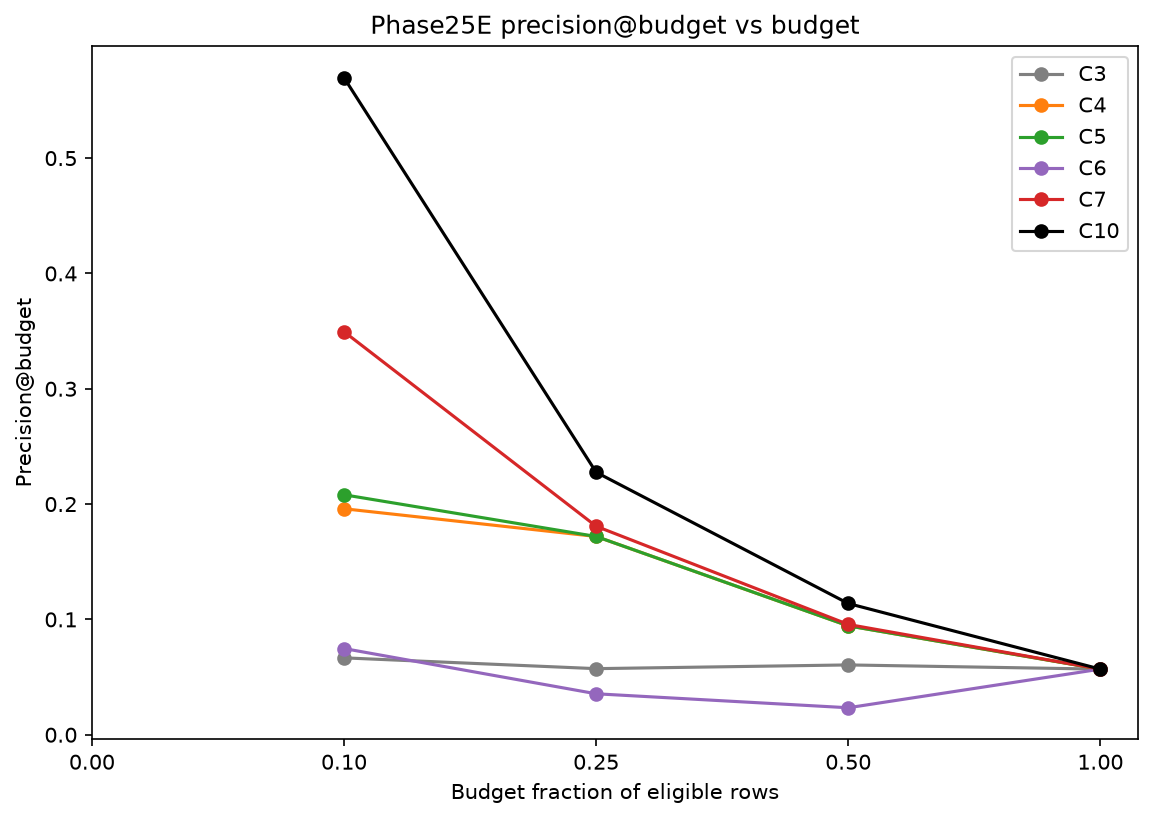

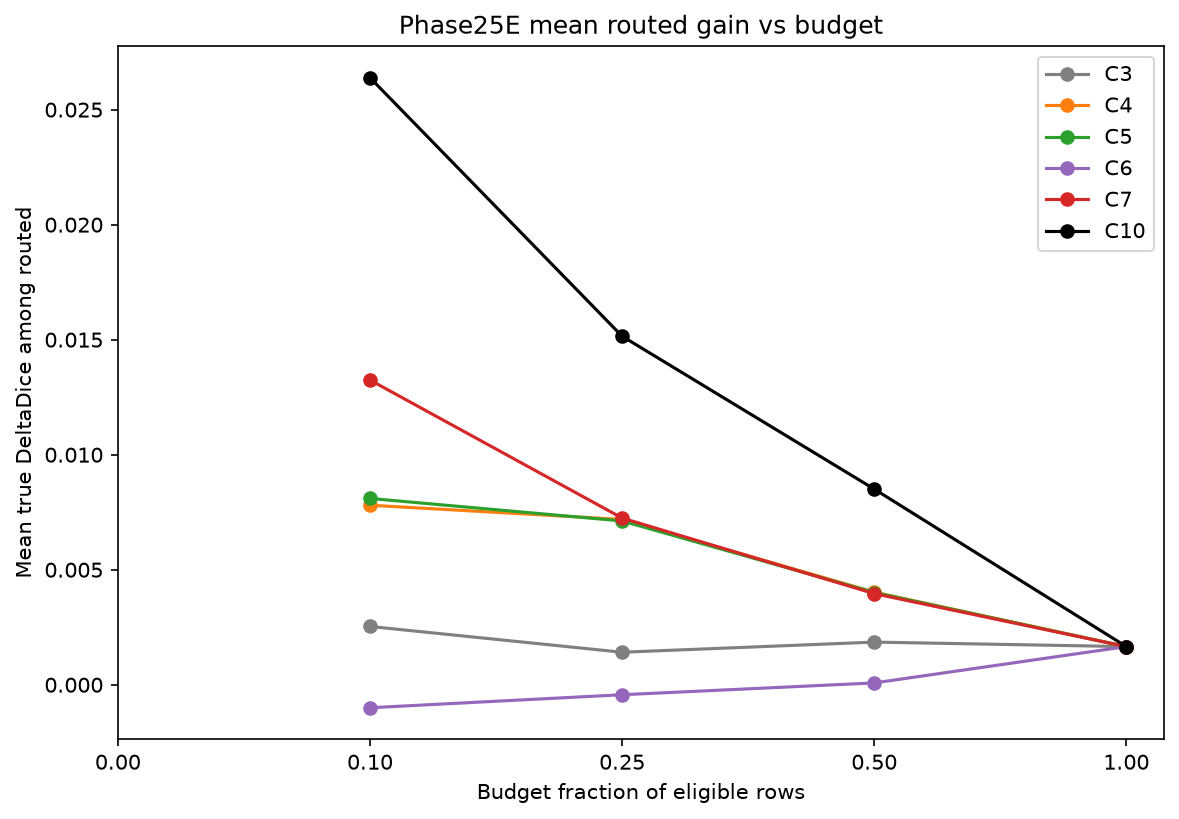

In [4]:
met = read_csv('reports/tables/phase25e_policy_evaluation_metrics.csv')
key = ['C1','C2','C3','C4','C5','C6','C7','C10']
sub = met[met.comparator.isin(key)][['comparator','budget','K','precision_at_budget',
      'mean_true_delta_dice_among_routed','benefit_capture_at_budget','harmful_activation_rate',
      'routing_regret_vs_oracle','average_total_analytical_macs']]
table(sub, 'Equal-budget policy metrics (C7/C8 identical under constant action cost)')
show_fig('reports/figures/p25e_precision_vs_budget.png')
show_fig('reports/figures/p25e_mean_delta_vs_budget.png')

## 4. Oracle upper bound and compute frontier

C10 is the nondeployable true-DeltaDice top-K upper bound.

policy_id,budget,K,precision_at_budget,mean_true_delta_dice_among_routed,benefit_capture_at_budget
C10_oracle_budget0.00,0.00,0,NaN,NaN,0.000000
C10_oracle_budget0.10,0.10,495,0.569697,0.026386,0.617830
C10_oracle_budget0.25,0.25,1239,0.227603,0.015150,0.887897
C10_oracle_budget0.50,0.50,2478,0.113801,0.008506,0.996996
C10_oracle_budget1.00,1.00,4957,0.056889,0.001658,1.000000


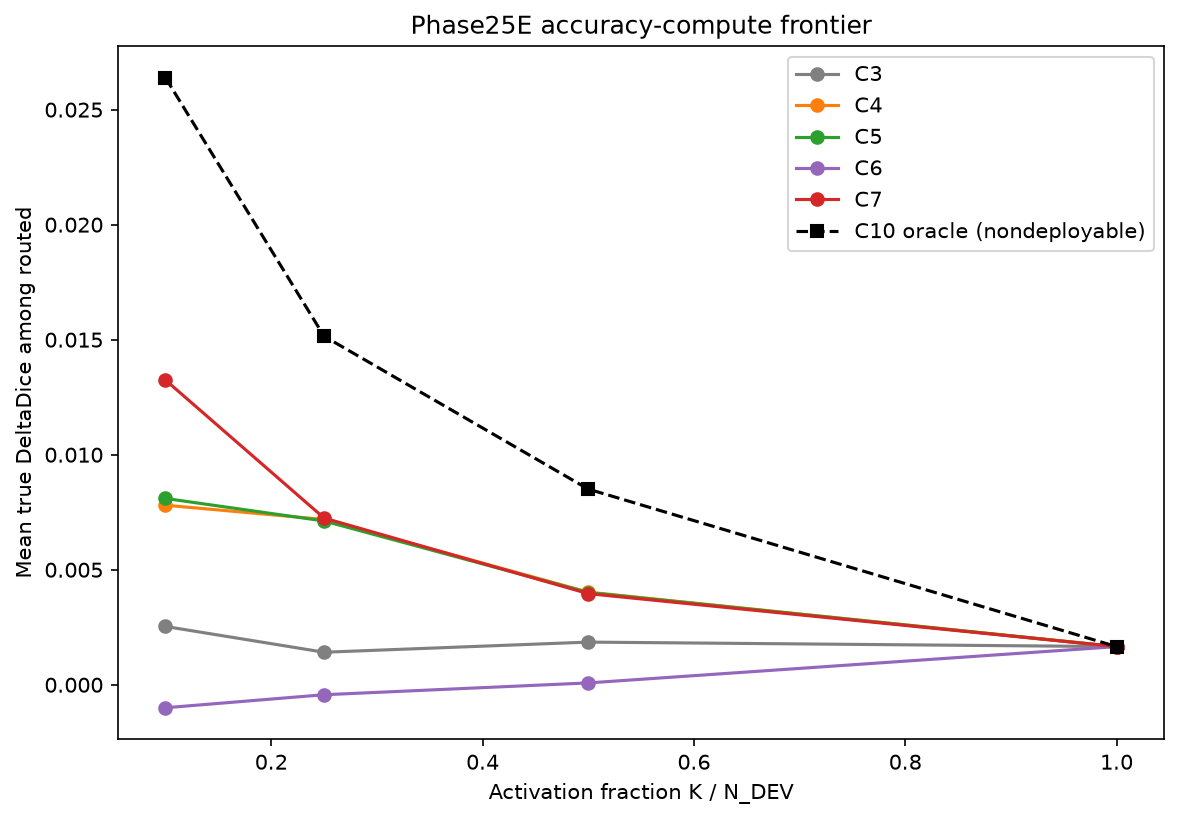

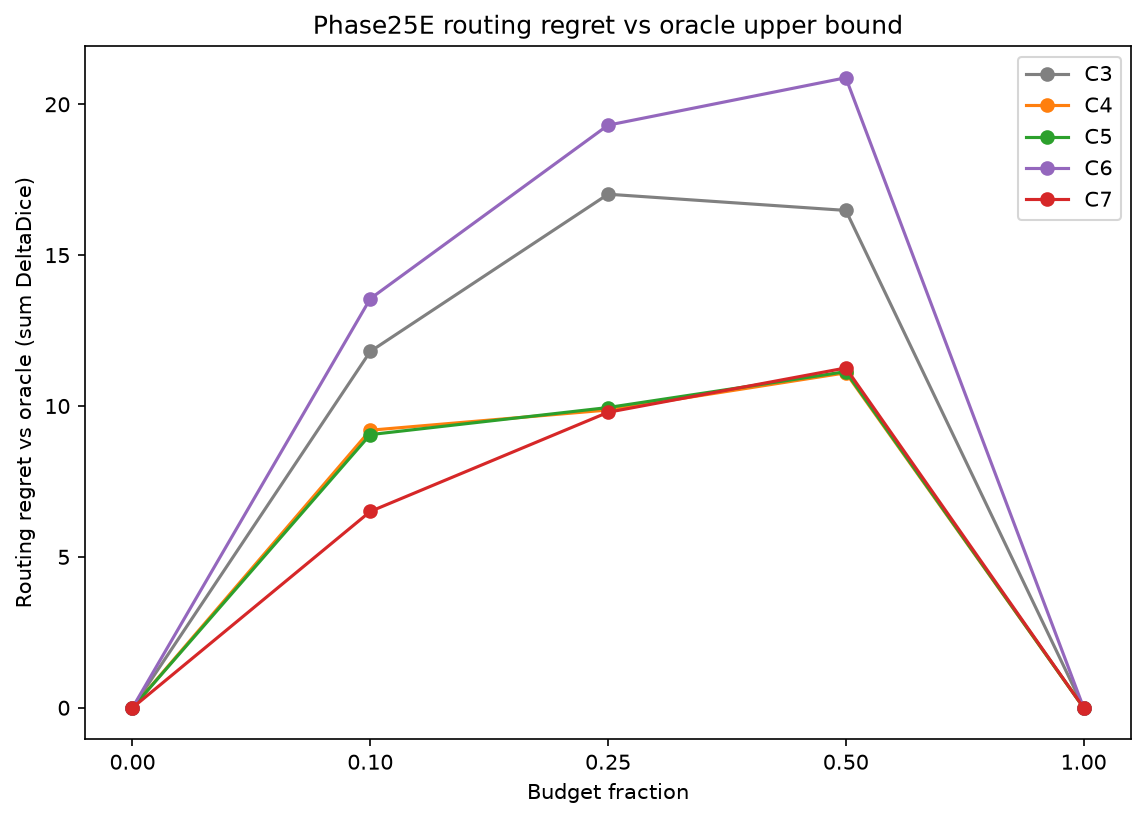

In [5]:
table(read_csv('reports/tables/phase25e_oracle_upper_bound.csv')[['policy_id','budget','K',
      'precision_at_budget','mean_true_delta_dice_among_routed','benefit_capture_at_budget']],
      'Oracle (C10) upper bound - NONDEPLOYABLE')
show_fig('reports/figures/p25e_compute_frontier.png')
show_fig('reports/figures/p25e_regret_vs_budget.png')

## 5. C7/C8 structural redundancy

Because the incremental action cost is constant across eligible rows, `lambda` cannot change the fixed-budget ranking.

lambda,budget,same_membership,same_precision,same_mean_true_delta,same_regret
0.00,0.00,True,True,True,True
0.00,0.10,True,True,True,True
0.00,0.25,True,True,True,True
0.00,0.50,True,True,True,True
0.00,1.00,True,True,True,True
0.25,0.00,True,True,True,True
0.25,0.10,True,True,True,True
0.25,0.25,True,True,True,True
0.25,0.50,True,True,True,True
0.25,1.00,True,True,True,True


all C7/C8 memberships equal: True


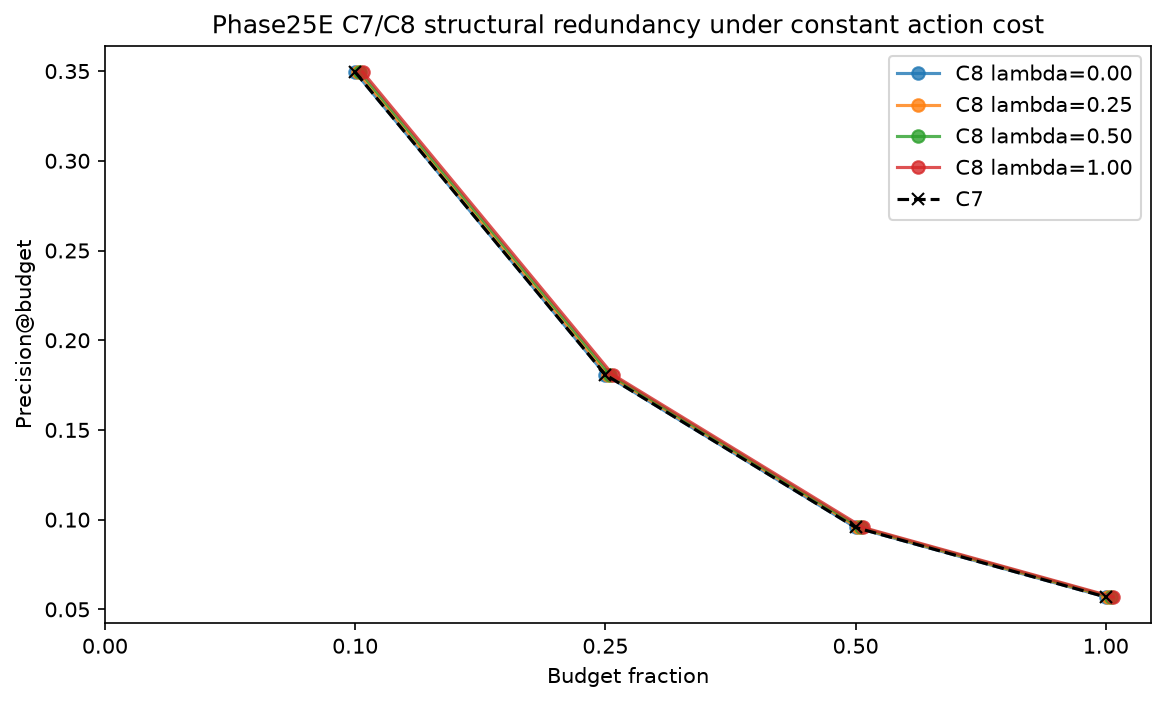

In [6]:
red = read_csv('reports/tables/phase25e_c7_c8_redundancy.csv')
table(red, 'C7/C8 membership and metric equivalence')
print('all C7/C8 memberships equal:', bool(red.same_membership.all()))
show_fig('reports/figures/p25e_c7_c8_redundancy.png')

## 6. Domain and size-stratum reporting

budget,domain,n_routed,mean_true_delta_dice,precision_at_budget,harmful_activation_rate
0.00,BUSI,0,NaN,NaN,NaN
0.00,ISIC,0,NaN,NaN,NaN
0.00,KUB,0,NaN,NaN,NaN
0.00,KVASIR,0,NaN,NaN,NaN
0.10,BUSI,0,NaN,NaN,NaN
0.10,ISIC,21,0.009431,0.285714,0.095238
0.10,KUB,474,0.013414,0.352321,0.126582
0.10,KVASIR,0,NaN,NaN,NaN
0.25,BUSI,6,0.000187,0.000000,0.000000
0.25,ISIC,360,0.003529,0.075000,0.086111


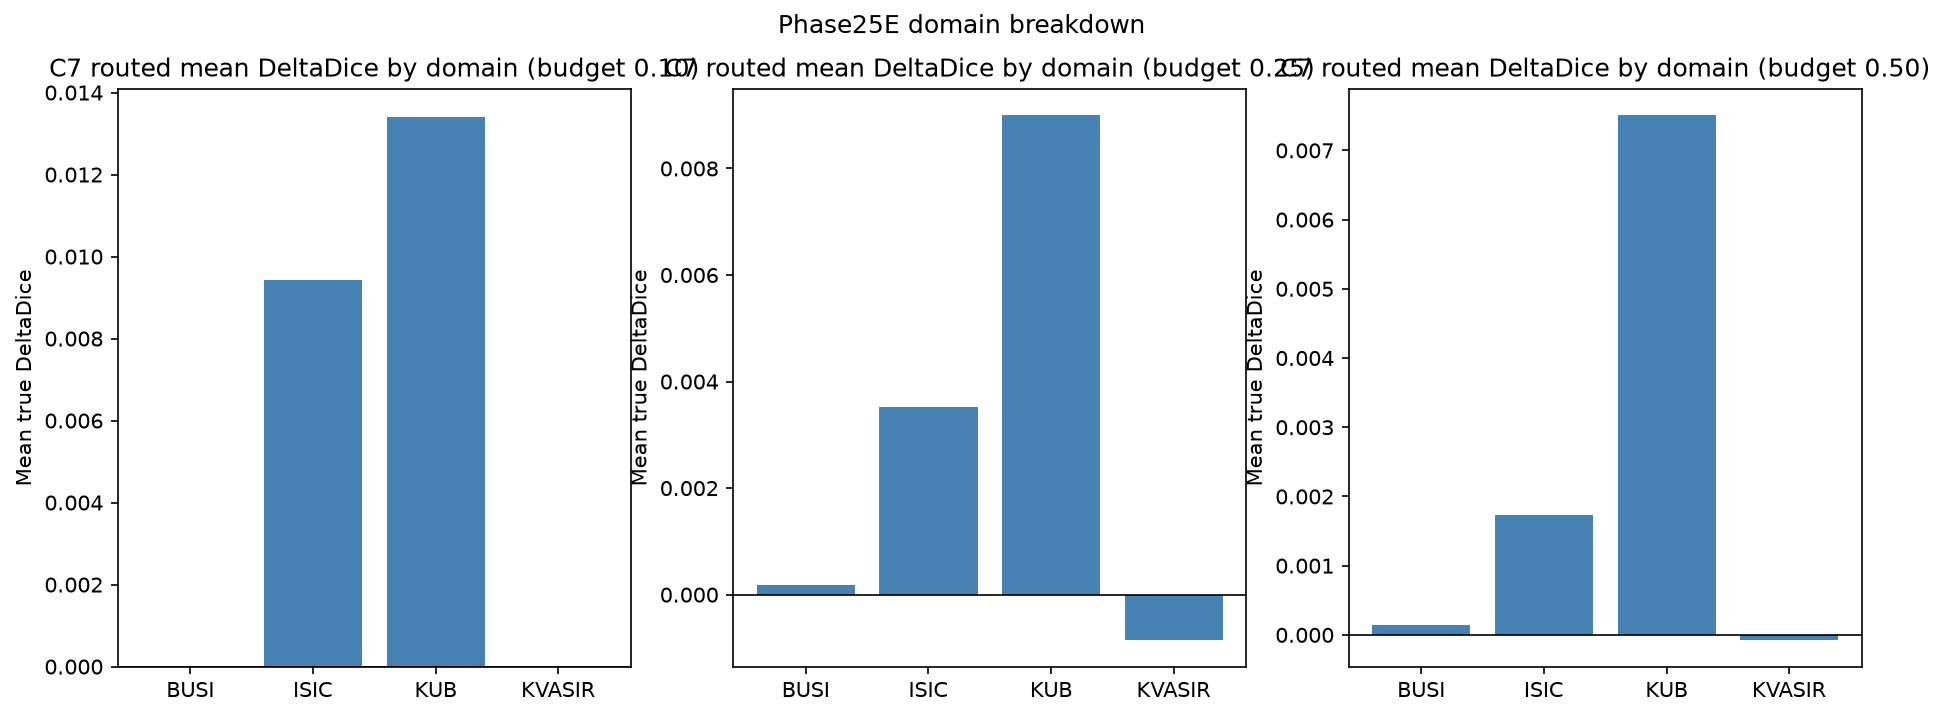

budget,size_stratum,n_routed,mean_true_delta_dice,precision_at_budget
0.00,Q1_tiny,0,NaN,NaN
0.00,Q2_small,0,NaN,NaN
0.00,Q3_medium,0,NaN,NaN
0.00,Q4_large,0,NaN,NaN
0.10,Q1_tiny,0,NaN,NaN
0.10,Q2_small,1,0.001868,0.000000
0.10,Q3_medium,354,0.015704,0.398305
0.10,Q4_large,140,0.007108,0.228571
0.25,Q1_tiny,51,-0.000652,0.039216
0.25,Q2_small,131,0.002691,0.053435


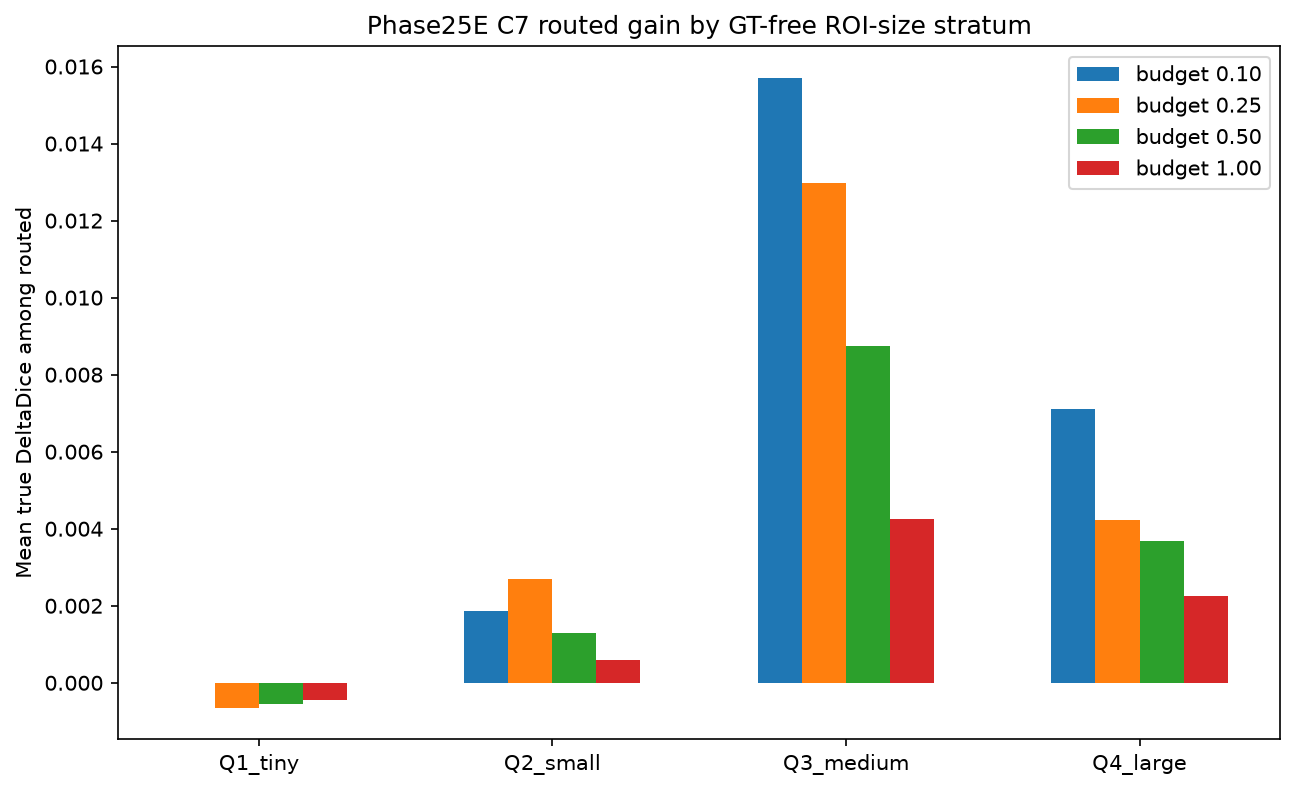

In [7]:
dom = read_csv('reports/tables/phase25e_domain_reporting.csv')
table(dom[(dom.comparator=='C7')][['budget','domain','n_routed','mean_true_delta_dice',
      'precision_at_budget','harmful_activation_rate']], 'C7 routed metrics by domain')
show_fig('reports/figures/p25e_domain_breakdown.png')
size = read_csv('reports/tables/phase25e_size_strata_reporting.csv')
table(size[(size.comparator=='C7')][['budget','size_stratum','n_routed','mean_true_delta_dice',
      'precision_at_budget']], 'C7 routed metrics by GT-free ROI-size stratum')
show_fig('reports/figures/p25e_size_strata.png')

## 7. Domain-stratified group bootstrap

2000 replicates, seed 42, percentile 95% CI, paired two-sided p (Holm-adjusted within the C7-vs-comparator family).

bootstrap: DOMAIN_STRATIFIED_GROUP_BOOTSTRAP | n_boot 2000 | seed 42
plan sha256: 918e971cfe5ac20a0c2306548604938a1a31e4cab210cff255141d7e65f39861


policy_id,precision_at_budget_mean,precision_at_budget_ci_low,precision_at_budget_ci_high,mean_true_delta_dice_among_routed_mean,mean_true_delta_dice_among_routed_ci_low,mean_true_delta_dice_among_routed_ci_high
C3_budget0.00,NaN,NaN,NaN,NaN,NaN,NaN
C3_budget0.10,0.065931,0.044444,0.089468,0.002486,0.001482,0.003541
C3_budget0.25,0.057846,0.044210,0.071890,0.001436,0.000491,0.002246
C3_budget0.50,0.060490,0.050589,0.070359,0.001850,0.001285,0.002390
C3_budget1.00,0.056948,0.049392,0.064752,0.001656,0.001216,0.002066
C4_budget0.00,NaN,NaN,NaN,NaN,NaN,NaN
C4_budget0.10,0.197480,0.161032,0.237223,0.007805,0.005839,0.009951
C4_budget0.25,0.171919,0.145423,0.199187,0.007168,0.005983,0.008425
C4_budget0.50,0.094562,0.080130,0.108778,0.004027,0.003405,0.004677
C4_budget1.00,0.056948,0.049392,0.064752,0.001656,0.001216,0.002066


budget,comparator,mean_diff,paired_p_raw,holm_adjusted_p,n_pairs
0.00,C1,NaN,NaN,NaN,NaN
0.00,C2,NaN,NaN,NaN,NaN
0.00,C3,NaN,NaN,NaN,NaN
0.00,C4,NaN,NaN,NaN,NaN
0.00,C5,NaN,NaN,NaN,NaN
0.00,C6,NaN,NaN,NaN,NaN
0.00,C10,NaN,NaN,NaN,NaN
0.10,C1,NaN,NaN,NaN,NaN
0.10,C2,0.291580,0.001000,0.005997,2000.0
0.10,C3,0.282597,0.001000,0.005997,2000.0


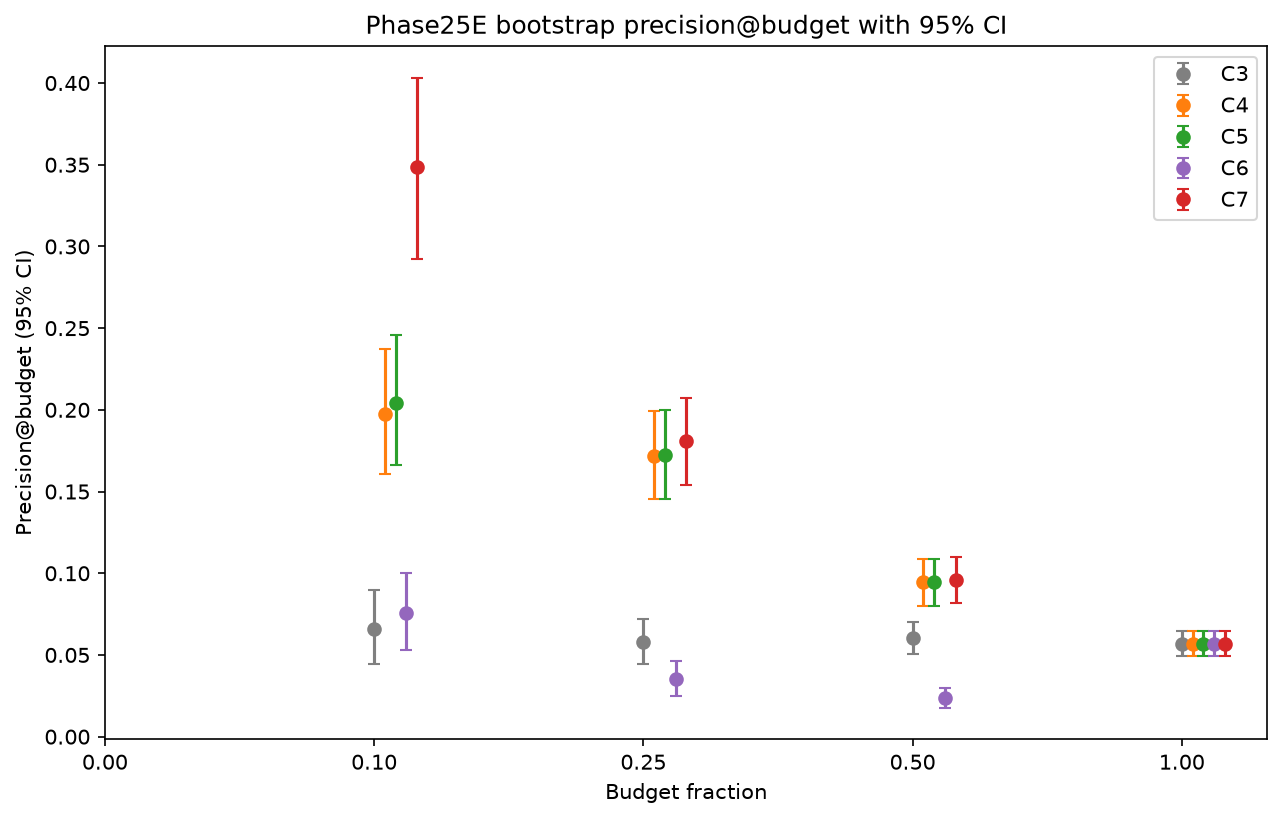

In [8]:
stats = read_json('reports/audits/phase25e_evaluation_statistics_contract_v1_0.json')
print('bootstrap:', stats['bootstrap_type'], '| n_boot', stats['n_boot'], '| seed', stats['seed'])
print('plan sha256:', stats['bootstrap_plan_sha256'])
boot = read_csv('reports/tables/phase25e_bootstrap_ci.csv')
sel = boot[boot.policy_id.str.match(r'C[3-7]_budget')][['policy_id','precision_at_budget_mean',
      'precision_at_budget_ci_low','precision_at_budget_ci_high','mean_true_delta_dice_among_routed_mean',
      'mean_true_delta_dice_among_routed_ci_low','mean_true_delta_dice_among_routed_ci_high']]
table(sel, 'Bootstrap CIs for deployable comparators')
paired = read_csv('reports/tables/phase25e_paired_bootstrap_tests.csv')
table(paired[(paired.metric=='precision_at_budget')][['budget','comparator','mean_diff','paired_p_raw','holm_adjusted_p','n_pairs']],
      'Paired tests: C7 vs comparators (precision@budget)')
show_fig('reports/figures/p25e_bootstrap_ci_precision.png')

## 8. Adjudication against the frozen Phase24 criteria

In [9]:
adj = read_json('reports/audits/phase25e_adjudication.json')
table(pd.DataFrame([
    ['S1 H1 status', adj['S1_H1_status']],
    ['S1 per-budget pass', json.dumps(adj['S1_budget_pass'])],
    ['F2 router failure', adj['F2_router_failure']],
    ['S2 preservation satisfied', adj['S2_preservation_satisfied']],
    ['F3 preservation failure', adj['F3_preservation_failure']],
    ['S3 frontier measured', adj['S3_frontier_measured']],
    ['F4 resource failure', adj['F4_resource_failure']],
    ['F5 domain collapse', adj['F5_domain_collapse_triggered']],
], columns=['criterion','outcome']), 'Phase24 criteria adjudication')
table(pd.DataFrame(adj['S1_detail']), 'S1 detail: C7 vs simple GT-free proxies (Holm-adjusted)')
summary = read_json('reports/audits/phase25e_policy_evaluation_summary.json')
print('policies:', summary['policy_count'], '| bootstrap replicates:', summary['bootstrap_replicates'])
print('holdout reads:', summary['router_holdout_reads'], '| VAL808:', summary['VAL808_reads'], '| TEST:', summary['TEST_reads'])

criterion,outcome
S1 H1 status,PARTIAL
S1 per-budget pass,"{""0.10"": true, ""0.25"": false, ""0.50"": false}"
F2 router failure,False
S2 preservation satisfied,True
F3 preservation failure,False
S3 frontier measured,True
F4 resource failure,False
F5 domain collapse,False


budget,comparator,precision_delta,mean_delta_gain,c7_wins_precision,c7_wins_mean,holm_adjusted_p,significant
0.10,C3,0.282828,0.010711,True,True,0.005997,True
0.10,C4,0.153535,0.005441,True,True,0.005997,True
0.10,C5,0.141414,0.005146,True,True,0.005997,True
0.10,C6,0.274747,0.014244,True,True,0.005997,True
0.25,C3,0.123487,0.005833,True,True,0.005997,True
0.25,C4,0.008878,0.000061,True,True,0.055972,False
0.25,C5,0.008878,0.000127,True,True,0.055972,False
0.25,C6,0.145278,0.007680,True,True,0.005997,True
0.50,C3,0.035109,0.002107,True,True,0.005997,True
0.50,C4,0.001211,-0.000065,True,False,0.651674,False


policies: 45 | bootstrap replicates: 2000
holdout reads: 0 | VAL808: 0 | TEST: 0


## 9. Conclusions (scoped)

- The learned paired-gain router (C7) **significantly beats every simple GT-free proxy on
  precision@budget at the tight budget (10%)**, with the advantage shrinking to statistical
  non-significance at 25% and 50% (entropy and margin proxies are competitive there).
- Preservation holds: the macro-domain mean routed gain lower 95% CI bound stays above
  -0.005 at every budget, and no domain collapse is observed.
- A usable accuracy-compute frontier exists across the five budget points (S3).
- `C8` is structurally redundant with `C7` under the constant incremental action cost.

**Scope guard**: `ROUTER_HOLDOUT`, `VAL808` and `TEST` were never read. The oracle is a
nondeployable development upper bound. H1 wording is therefore scoped to the integrated
GT-free paired-gain router at tight budgets (Level-2 novelty).

## 10. Post-closure statistical-adjudication reconciliation (addendum)

**Status**: additive reconciliation of the Phase25E closure. No raw scientific value is
changed — no membership, bootstrap replicate, model weight, prediction or metric is
recomputed. Only the *decision rule* used for the S1/H1 significance call is repaired.

**Finding.** The frozen Phase24 pre-registration declares a paired bootstrap with a
"paired p-value where appropriate" and **no multiplicity correction at all**. The frozen
Phase25E statistics contract (`phase25e_evaluation_statistics_contract_v1_0.json`) states
verbatim:

> `multiplicity`: *primary = raw paired two-sided p; secondary = Holm-Bonferroni within the
> pre-declared C7-vs-comparator family (C1..C6, C10)*

The post-outcome closure adjudication nonetheless used **Holm-Bonferroni as the primary
significance gate**. Holm was therefore never pre-registered as the *primary* rule; promoting
it to primary is an **unauthorized extension** of the frozen protocol. The reconciliation
restores the frozen primary statistic (the raw paired two-sided p) and retains Holm only as a
conservative secondary sensitivity. This follows from protocol provenance, **not** from which
result looks stronger.

In [10]:
prov = read_json('reports/audits/phase25e_multiplicity_provenance_audit.json')
print('classification:', prov['classification_code'], '-', prov['classification_label'])
print('frozen multiplicity clause:', prov['frozen_multiplicity_clause'])
print('Phase24 pre-registration artifacts mentioning multiplicity:',
      len(prov['phase24_artifacts_mentioning_multiplicity']))
print('material sensitivity rows (raw p vs Holm):', prov['material_sensitivity_count'])

classification: B - HOLM_NOT_PRE_REGISTERED__UNAUTHORIZED_PRIMARY_ADJUDICATION_EXTENSION
frozen multiplicity clause: primary = raw paired two-sided p; secondary = Holm-Bonferroni within the pre-declared C7-vs-comparator family (C1..C6, C10)
Phase24 pre-registration artifacts mentioning multiplicity: 0
material sensitivity rows (raw p vs Holm): 2


### 10.1 Primary (raw paired p) vs secondary (Holm) adjudication

The table below reports every budget/comparator/metric where the raw paired two-sided p and the
Holm-adjusted p give a different 5% significance call. Exactly two precision rows flip — both at
the 25% budget.

In [11]:
rec = read_json('reports/audits/phase25e_adjudication_reconciled.json')
sens = read_csv('reports/tables/phase25e_s1_primary_vs_multiplicity_sensitivity.csv')
table(sens[sens.metric=='precision_at_budget'][['budget','comparator','mean_diff','paired_p_raw',
      'raw_significant_at_0.05','holm_adjusted_p','holm_significant_at_0.05',
      'primary_decision_changed_by_holm']],
      'S1 precision@budget: PRIMARY raw p vs SECONDARY Holm')
table(pd.DataFrame([
    ['primary decision rule', rec['primary_decision_rule']],
    ['secondary decision rule', rec['secondary_decision_rule']],
    ['holm primary role', rec['holm_primary_role']],
    ['holm secondary role', rec['holm_secondary_role']],
    ['S1/H1 (PRIMARY, raw p)', rec['S1_H1_status']],
    ['S1 budget pass (PRIMARY)', json.dumps(rec['S1_budget_pass'])],
    ['S1/H1 (SECONDARY, Holm)', rec['S1_status_under_secondary_holm']],
    ['S1 budget pass (SECONDARY)', json.dumps(rec['S1_budget_pass_under_secondary_holm'])],
    ['closure original S1/H1', rec['closure_original_S1_H1_status']],
    ['closure original budget pass', json.dumps(rec['closure_original_budget_pass'])],
    ['F2 router failure', rec['F2_router_failure']],
], columns=['item','value']), 'Reconciled adjudication: PRIMARY vs SECONDARY')

budget,comparator,mean_diff,paired_p_raw,raw_significant_at_0.05,holm_adjusted_p,holm_significant_at_0.05,primary_decision_changed_by_holm
0.10,C3,0.282597,0.001000,True,0.005997,True,False
0.10,C4,0.151048,0.001000,True,0.005997,True,False
0.10,C5,0.144183,0.001000,True,0.005997,True,False
0.10,C6,0.272659,0.001000,True,0.005997,True,False
0.25,C3,0.122882,0.001000,True,0.005997,True,False
0.25,C4,0.008809,0.027986,True,0.055972,False,True
0.25,C5,0.008592,0.035982,True,0.055972,False,True
0.25,C6,0.145231,0.001000,True,0.005997,True,False
0.50,C3,0.035258,0.001000,True,0.005997,True,False
0.50,C4,0.001186,0.325837,False,0.651674,False,False


item,value
primary decision rule,paired_p_raw < 0.05 (frozen PRIMARY statistic)
secondary decision rule,holm_adjusted_p < 0.05 (retained as conservative sensitivity only)
holm primary role,SUPERSEDED_FOR_PRIMARY_ADJUDICATION
holm secondary role,CONSERVATIVE_MULTIPLICITY_SENSITIVITY
"S1/H1 (PRIMARY, raw p)",PARTIAL
S1 budget pass (PRIMARY),"{""0.10"": true, ""0.25"": true, ""0.50"": false}"
"S1/H1 (SECONDARY, Holm)",PARTIAL
S1 budget pass (SECONDARY),"{""0.10"": true, ""0.25"": false, ""0.50"": false}"
closure original S1/H1,PARTIAL
closure original budget pass,"{""0.10"": true, ""0.25"": false, ""0.50"": false}"


**Repaired result.** Under the frozen PRIMARY statistic (raw paired two-sided p), C7 beats
all four simple GT-free proxies on precision@budget at the **10% and 25%** budgets, and the
advantage is not significant at the 50% budget. The headline criterion S1/H1 remains
**PARTIAL** (two of three informative budgets pass), but the 25% budget now passes, whereas the
original Holm-primary closure recorded it as failing. Under the conservative secondary Holm
sensitivity only the 10% budget passes. F2 (router failure) is not triggered under either rule.

### 10.2 Preservation scope and corrected model-execution wording

Two wording records are clarified without touching any number: the exact scope of the S2
preservation claim, and the exact model-execution inventory of the evaluation.

In [12]:
psc = read_json('reports/audits/phase25e_preservation_scope_clarification.json')
mex = read_json('reports/audits/phase25e_model_execution_wording_reconciliation.json')
print('S2 preservation satisfied:', psc['satisfied'], '| all macro CI lows > -0.005:',
      psc['all_ci_lows_above_minus_0.005'], '| domain collapse:', psc['domain_collapse_triggered'])
print('preservation covers:', psc['what_the_claim_covers'][0])
print('preservation does NOT cover:', psc['what_the_claim_does_NOT_cover'][0])
print('---')
print('router forwards (frozen inventory):', mex['execution_inventory_frozen']['router_forwards'],
      'over', mex['execution_inventory_frozen']['router_forward_scope'])
print('global forwards:', mex['execution_inventory_frozen']['global_model_forwards'],
      '| refiner forwards:', mex['execution_inventory_frozen']['regional_refiner_forwards'],
      '| training runs:', mex['execution_inventory_frozen']['training_runs'])
print('reconciled wording:', mex['reconciled_wording'])

S2 preservation satisfied: True | all macro CI lows > -0.005: True | domain collapse: False
preservation covers: NON-INFERIORITY of the routed system vs the frozen global reference on the macro-domain mean true paired DeltaDice, on ROUTER_DEVELOPMENT (4957), at the frozen budget grid.
preservation does NOT cover: It is NOT a per-domain IMPROVEMENT claim. Routed benefit is strongly heterogeneous: KUB carries most of the positive mean; BUSI and KVASIR are near zero and KVASIR is marginally negative at 0.25/0.50 (but far above the -0.01 collapse threshold).
---
router forwards (frozen inventory): 1 over ROUTER_DEVELOPMENT (4957 rows), outcome-blind
global forwards: 0 | refiner forwards: 0 | training runs: 0
reconciled wording: Phase25E loaded the frozen final benefit-router checkpoint once and ran a single outcome-blind forward pass over the 4,957 ROUTER_DEVELOPMENT feature rows to fix the DEV deployment-score ranking and per-budget rank boundaries. No global segmentation model was re-run

### 10.3 Statements in this notebook that are SUPERSEDED

The following statements, carried over unchanged from the pre-reconciliation build, are
superseded by the reconciliation above and must not be quoted as the current Phase25E result:

- Section 7 / Section 9: that the C7 advantage is significant **only at the 10% budget** and
  non-significant at 25%/50% — under the frozen primary statistic it is significant at
  **10% and 25%**, non-significant only at 50%. (The 25%/50% phrasing reflected the
  Holm-as-primary extension.)
- Any phrasing that implies the evaluation loaded or ran no model at all — exactly **one
  outcome-blind forward pass of the frozen final router** over the 4,957 DEV rows was
  executed; no global-model forward, no refiner forward, no training.

The authoritative primary adjudication is `reports/audits/phase25e_adjudication_reconciled.json`;
the original closure adjudication `reports/audits/phase25e_adjudication.json` is retained
unchanged as provenance.

**Reconciliation terminal**:
`PHASE25E_CANONICAL_ADJUDICATION_REPAIRED__PRIMARY_PHASE24_STATISTICS_RESTORED__HOLM_RETAINED_AS_SENSITIVITY__PHASE25F_ELIGIBLE_NOT_STARTED`.